In [1]:
from LunaTrek import *
import matplotlib.pyplot as plt

In [2]:
phi, lamb = -89.67, 129.78

In [3]:
df = makeDF("2026-11-11T12:00:00Z", "2027-11-11T12:00:00Z")

In [9]:
lat, long = -89.67, 129.78
# lat, long = -89.5343, -150.05
_, _, elev, slope = getMoonState(lat, long)
df = calcRVect(lat, long, df)

In [10]:
Spts = df[['SX', 'SY', 'SZ']].to_numpy()
Epts = df[['EX', 'EY', 'EZ']].to_numpy()

df['SCritTheta'], df['SAzimuthal'] = getCritAzimuthalAngle(lat, long, Spts, elevation_grid, dem_transform)
df['ECritTheta'], df['EAzimuthal'] = getCritAzimuthalAngle(lat, long, Epts, elevation_grid, dem_transform)

In [11]:
df.head()

,datetime_utc,iso_utc_str,et,SX,SY,SZ,EX,EY,EZ,PSX,...,PSZ,PEX,PEY,PEZ,STheta,ETheta,SCritTheta,SAzimuthal,ECritTheta,EAzimuthal
0,2026-11-11 12:00:00+00:00,2026-11-11T12:00:00Z,8.476705e+08,-1.360644e+08,5.746467e+07,-4.002919e+06,400647.517211,13681.071816,43870.327055,-1.360643e+08,...,-4.001185e+06,400653.909603,13673.393981,45604.909304,1.844920,-6.692372,20.098165,27.328482,21.737097,-127.795260
1,2026-11-11 14:00:00+00:00,2026-11-11T14:00:00Z,8.476777e+08,-1.350231e+08,5.986955e+07,-4.003709e+06,400853.859612,13033.402988,43631.219868,-1.350230e+08,...,-4.001974e+06,400860.252004,13025.725153,45365.802117,1.847872,-6.656110,20.040541,26.311728,21.734853,-127.888942
2,2026-11-11 16:00:00+00:00,2026-11-11T16:00:00Z,8.476849e+08,-1.339394e+08,6.225556e+07,-4.004473e+06,401056.059090,12377.555740,43378.215698,-1.339394e+08,...,-4.002738e+06,401062.451482,12369.877905,45112.797946,1.850719,-6.617975,20.006985,25.294994,21.732634,-127.983695
3,2026-11-11 18:00:00+00:00,2026-11-11T18:00:00Z,8.476921e+08,-1.328136e+08,6.462196e+07,-4.005211e+06,401253.927147,11713.636907,43111.411085,-1.328136e+08,...,-4.003477e+06,401260.319539,11705.959072,44845.993334,1.853462,-6.577982,20.018798,24.278280,21.720717,-128.079505
4,2026-11-11 20:00:00+00:00,2026-11-11T20:00:00Z,8.476993e+08,-1.316462e+08,6.696800e+07,-4.005925e+06,401447.273783,11041.760716,42830.906283,-1.316462e+08,...,-4.004190e+06,401453.666175,11034.082880,44565.488532,1.856099,-6.536148,19.999375,23.261586,21.717982,-128.176355


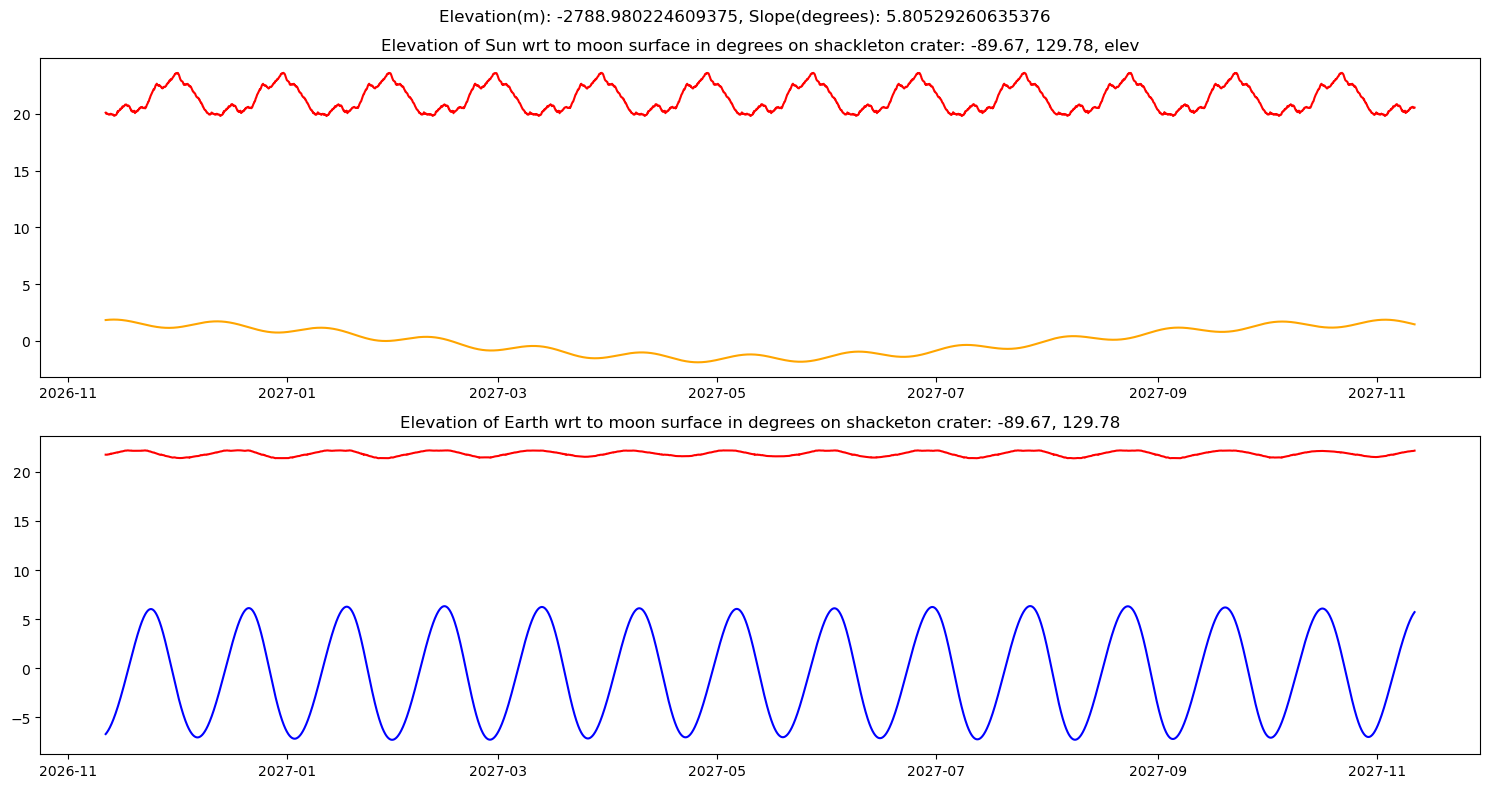

In [12]:
fig, axs = plt.subplots(2, 1, figsize = (15, 8))

fig.suptitle("Elevation(m): {}, Slope(degrees): {}".format(elev, slope))
axs[0].plot(df['datetime_utc'], df['STheta'], color='orange')
axs[0].plot(df['datetime_utc'], df['SCritTheta'], color='red', linestyle='-')
axs[0].set_title("Elevation of Sun wrt to moon surface in degrees on shackleton crater: {}, {}, elev".format(lat, long))

axs[1].plot(df['datetime_utc'], df['ETheta'], color='blue')
axs[1].plot(df['datetime_utc'], df['ECritTheta'], color='red', linestyle='-')
axs[1].set_title("Elevation of Earth wrt to moon surface in degrees on shacketon crater: {}, {}".format(lat, long))

plt.tight_layout()
plt.show()

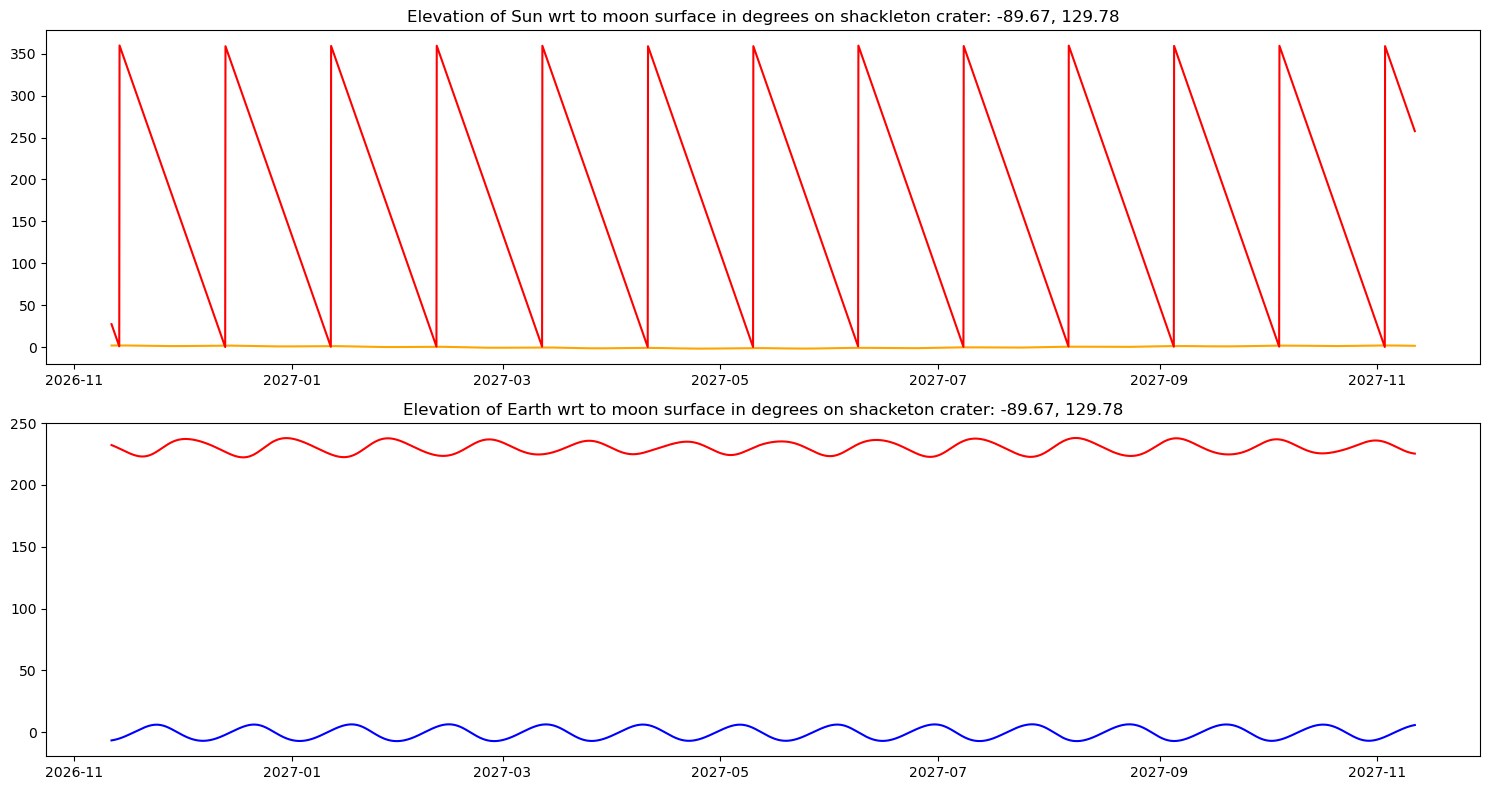

In [14]:
fig, axs = plt.subplots(2, 1, figsize = (15, 8))

axs[0].plot(df['datetime_utc'], df['STheta'], color='orange')
axs[0].plot(df['datetime_utc'], df['SAzimuthal'] % 360, color='red', linestyle='-')
axs[0].set_title("Elevation of Sun wrt to moon surface in degrees on shackleton crater: {}, {}".format(phi, lamb))

axs[1].plot(df['datetime_utc'], df['ETheta'], color='blue')
axs[1].plot(df['datetime_utc'], df['EAzimuthal'] % 360, color='red', linestyle='-')
axs[1].set_title("Elevation of Earth wrt to moon surface in degrees on shacketon crater: {}, {}".format(phi, lamb))

plt.tight_layout()
plt.show()

/home/omsai/.conda/envs/torchtut/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


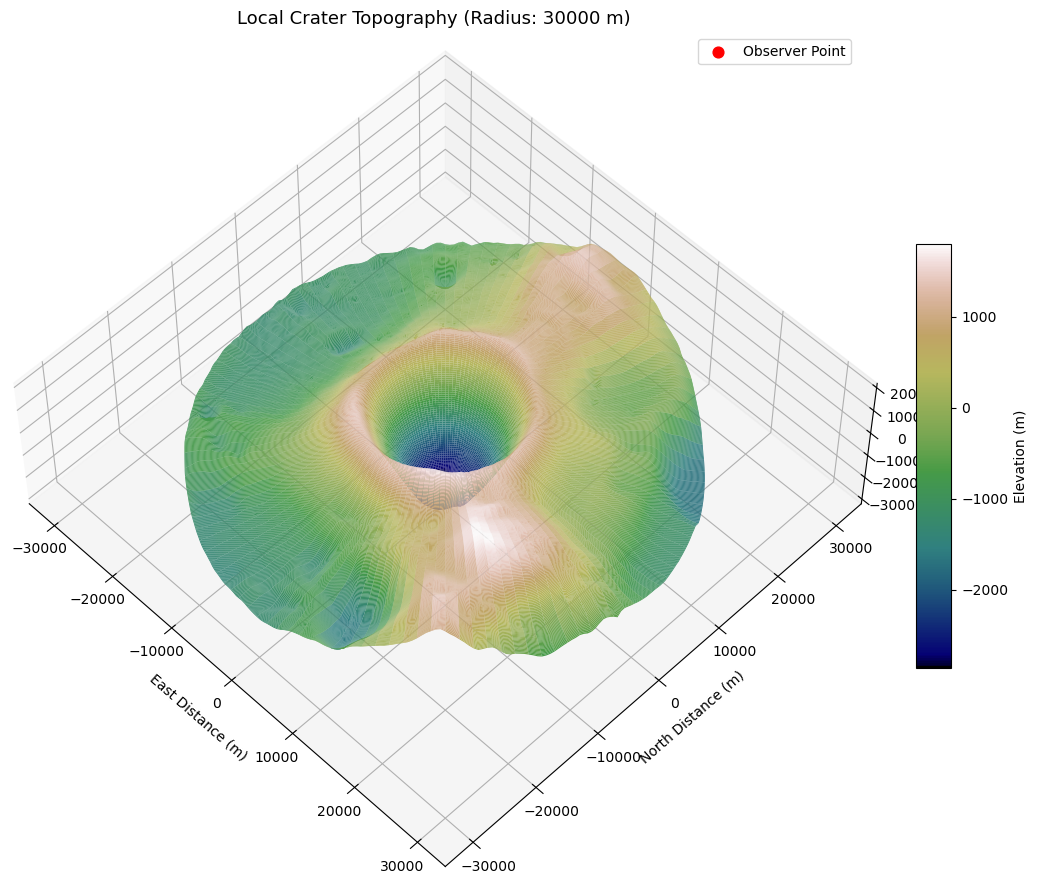

In [8]:
X_east, Y_north, eleveff = get360profile(phi, lamb)

# 3. Plot with a higher camera angle and wider base aspect ratio
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(
    X_east,
    Y_north,
    eleveff,
    cmap='gist_earth',      # High-contrast terrain colormap for crater rims/floors
    edgecolor='none',
    antialiased=True,
    rcount=180,             # Smooth angular resolution
    ccount=300              # Smooth radial resolution
)

# Mark the observer's exact position at the center (0, 0)
_, _, obs_elev, _ = getMoonState(phi, lamb)
ax.scatter([0], [0], [obs_elev], color='red', s=60, label='Observer Point', zorder=10)

# 4. Widen the base visually and tilt camera to look INTO the craters
ax.set_box_aspect((1, 1, 0.35))  # Stretches X and Y relative to Z (flattens steep walls)
ax.view_init(elev=55, azim=-45)  # Higher 'elev' (50-70 deg) looks down into crater bowls

ax.set_title(f"Local Crater Topography (Radius: 30000 m)", fontsize=13)
ax.set_xlabel("East Distance (m)")
ax.set_ylabel("North Distance (m)")
ax.set_zlabel("Effective Elevation (m)")
ax.legend()
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=12, label="Elevation (m)")

plt.tight_layout()
plt.show()